┌ Warning: Found `resolution` in the theme when creating a `Scene`. The `resolution` keyword for `Scene`s and `Figure`s has been deprecated. Use `Figure(; size = ...` or `Scene(; size = ...)` instead, which better reflects that this is a unitless size and not a pixel resolution. The key could also come from `set_theme!` calls or related theming functions.
└ @ Makie C:\Users\vishw\.julia\packages\Makie\4JW9B\src\scenes.jl:264


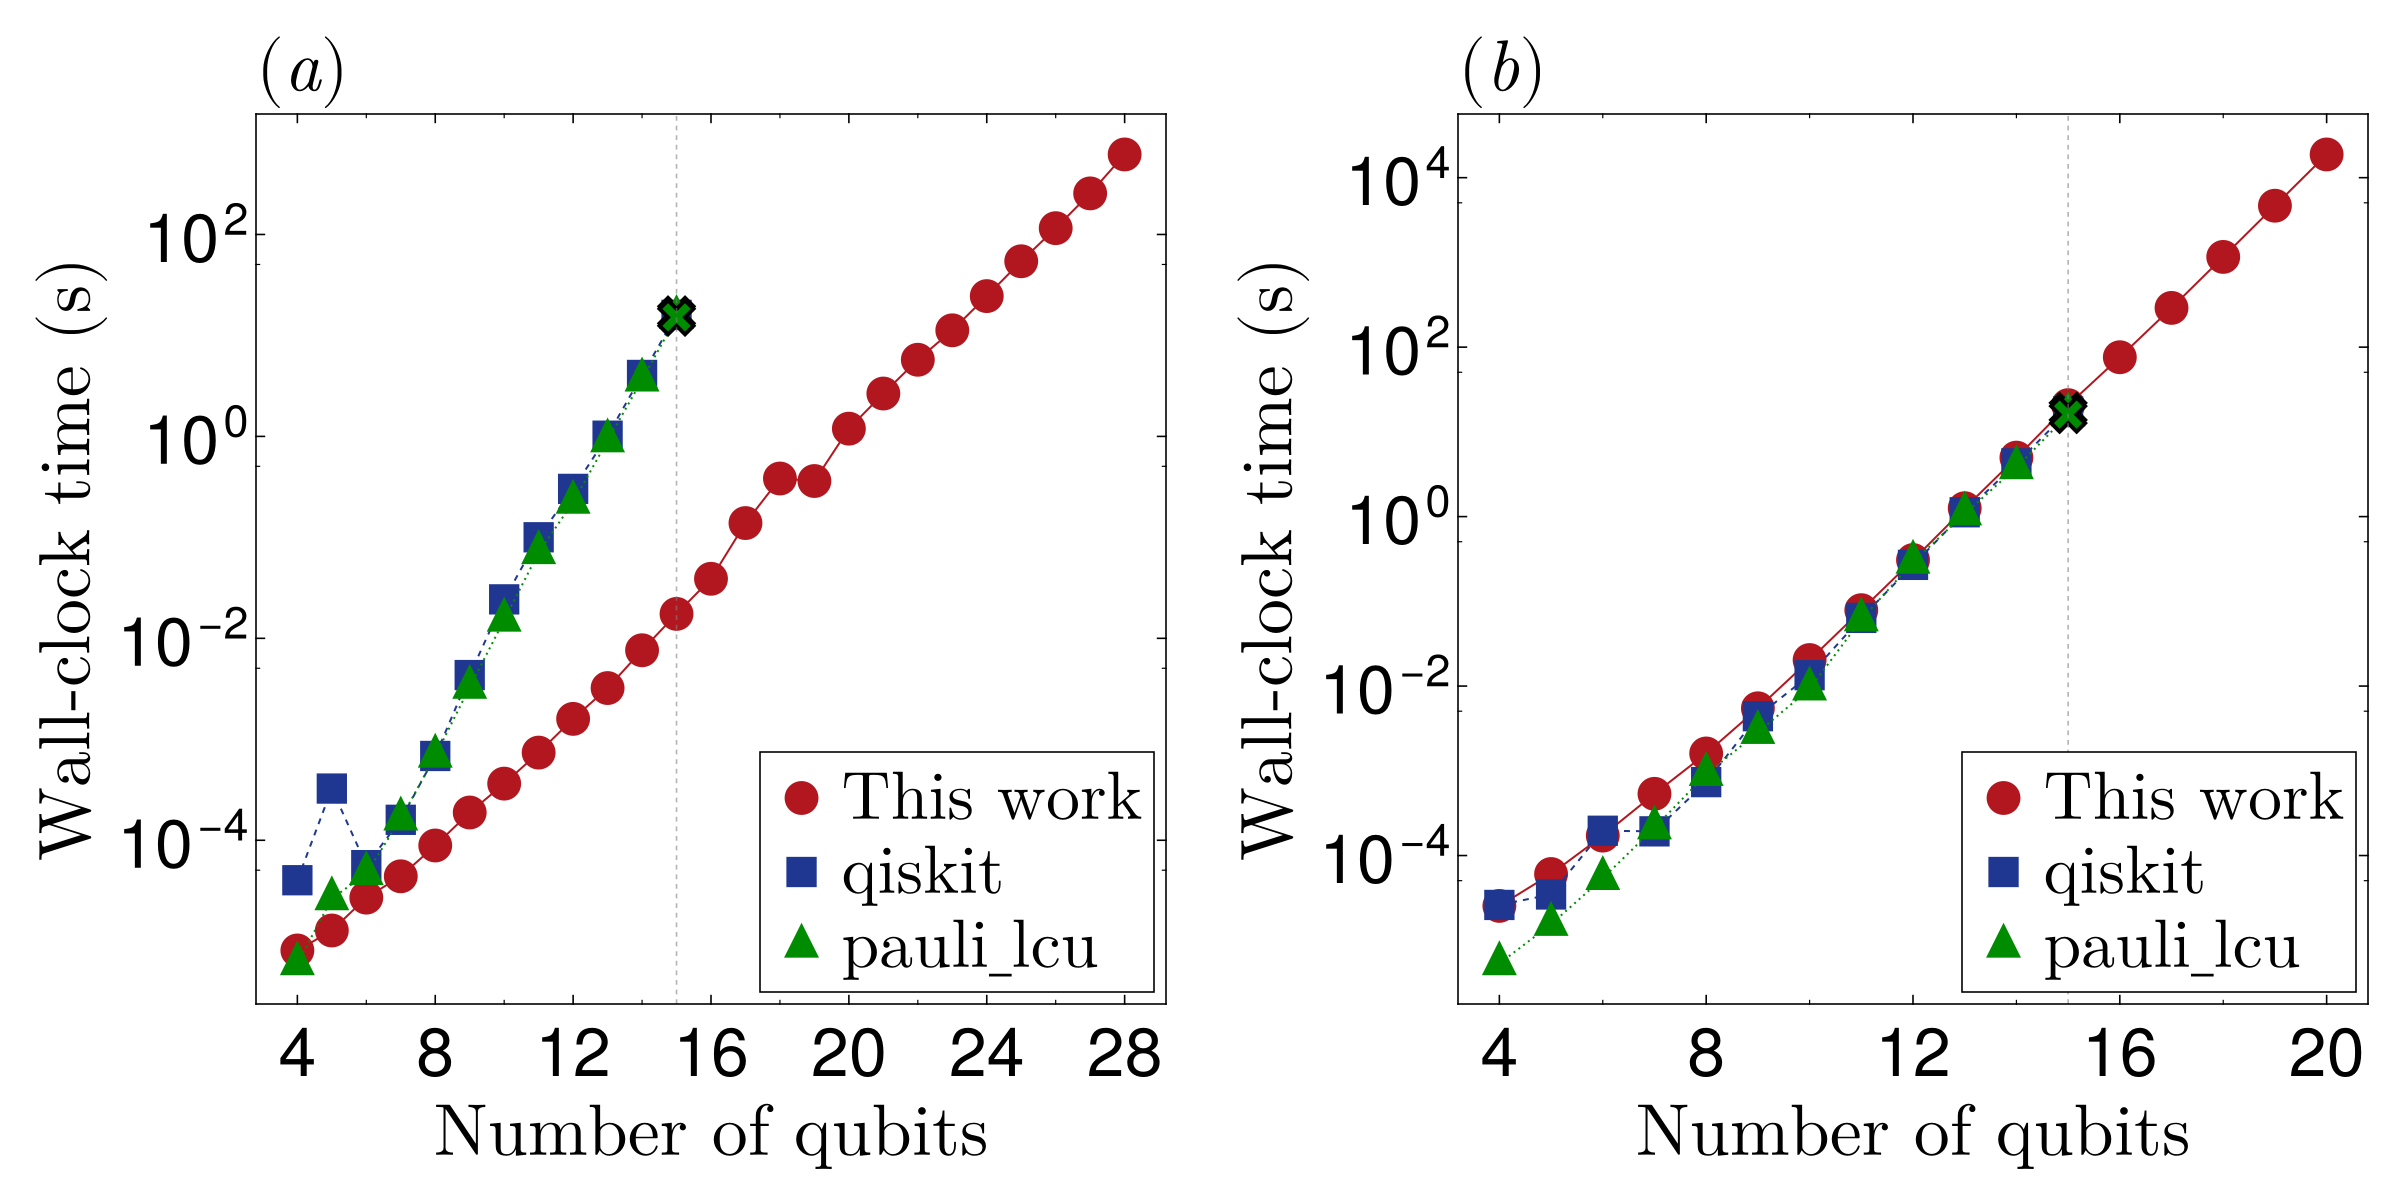

In [ ]:
using CairoMakie, CSV, DataFrames

vline_x      = 15
vline_color  = (:grey, 0.6)
vline_width  = 0.8
vline_style  = :dash

lap_py  = CSV.read("pauli_decomp_python_times_laplacian.csv", DataFrame)[4:end, :]
leg_py  = CSV.read("pauli_decomp_python_times_legendre.csv",  DataFrame)[4:end, :]

lap_jl  = CSV.read("pauli_decomp_julia_times_laplacian3.csv",  DataFrame)[3:end, :]
leg_jl  = CSV.read("pauli_decomp_julia_times_legendre.csv",   DataFrame)[3:end, :]

lap_plc = CSV.read("pauli_lcu_laplacian.csv", DataFrame)[4:end, :]
leg_plc = CSV.read("pauli_lcu_legendre.csv", DataFrame)[4:end, :]

QISKIT_FAIL = 15
PLC_FAIL     = 15

CairoMakie.set_theme!(Theme(
    fontsize = 11,
    font = "Times New Roman",
    Axis = (
        xgridvisible = false,
        ygridvisible = false,
		xlabelsize = 36,
		ylabelsize = 36,
		xticklabelsize = 34,
		yticklabelsize = 34,
		titlesize = 36,
        spinewidth = 0.8,
        xtickwidth = 0.8,
        ytickwidth = 0.8,
        xticksize = 5,
        yticksize = 5,
        xminorticksize = 2.5,
        yminorticksize = 2.5,
        xminorticksvisible = true,
        yminorticksvisible = true,
        xminortickwidth = 0.6,
        yminortickwidth = 0.6,
        ticklabelfont = "Times New Roman",
        labelfont = "Times New Roman",
        titlefont = "Times New Roman",
        xticklabelpad = 3,
        yticklabelpad = 3,
		xtickalign = 1,
		ytickalign = 1,
		xminortickalign = 1,
		yminortickalign = 1,
		xticksmirrored = true,
		yticksmirrored = true,
    ),
))


COLOR_JULIA  = RGBf(0.698, 0.090, 0.122)   # red
COLOR_QISKIT = RGBf(0.122, 0.216, 0.569)   # navy
COLOR_PLC    = RGBf(0.000, 0.550, 0.000)   # green


fig = Figure(resolution = (1200, 600), backgroundcolor = :white)

ax1 = Axis(fig[1, 1],
    xlabel = L"Number of qubits$$",
    ylabel = L"Wall-clock time (s)$$",
    yscale = log10,
    title  = L"(a)",
    titlealign = :left,
    titlegap = 3,
    xticks = (4:4:28, string.(4:4:28)),
    xminorticks = IntervalsBetween(2),
)

ax2 = Axis(fig[1, 2],
    xlabel = L"Number of qubits$$",
    ylabel = L"Wall-clock time (s)$$",
    yscale = log10,
    title  = L"(b)",
    titlealign = :left,
    titlegap = 3,
    xticks = (4:4:20, string.(4:4:20)),
    xminorticks = IntervalsBetween(2),
)


function plot_panel!(ax, py_df, jl_df, plc_df)


    l1 = lines!(ax, jl_df.num_qubits, jl_df.time_julia;
        color = COLOR_JULIA,
        linewidth = 1.0)

    s1 = scatter!(ax, jl_df.num_qubits, jl_df.time_julia;
        color = COLOR_JULIA,
        marker = :circle,
        markersize = 24,
        strokewidth = 0)

    qiskit_valid = py_df[py_df.num_qubits .<= QISKIT_FAIL, :]

    l2 = lines!(ax, qiskit_valid.num_qubits, qiskit_valid.time_qiskit;
        color = COLOR_QISKIT,
        linewidth = 1.0,
        linestyle = :dash)

    s2 = scatter!(ax, qiskit_valid.num_qubits, qiskit_valid.time_qiskit;
        color = COLOR_QISKIT,
        marker = :rect,
        markersize = 24,
        strokewidth = 0)

    # Qiskit failure marker 
    last_row = qiskit_valid[qiskit_valid.num_qubits .== QISKIT_FAIL, :]
    scatter!(ax, [QISKIT_FAIL], [last_row.time_qiskit[1]];
        color = COLOR_QISKIT,
        marker = :xcross,
        markersize = 24,
        strokewidth = 2)

    plc_valid = plc_df[plc_df.num_qubits .<= PLC_FAIL, :]

    l3 = lines!(ax, plc_valid.num_qubits, plc_valid.time_paulilcu;
        color = COLOR_PLC,
        linewidth = 1.0,
        linestyle = :dot)

    s3 = scatter!(ax, plc_valid.num_qubits, plc_valid.time_paulilcu;
        color = COLOR_PLC,
        marker = :utriangle,
        markersize = 24,
        strokewidth = 0)

    # PLC failure marker 
    last_row = plc_valid[plc_valid.num_qubits .== PLC_FAIL, :]
    scatter!(ax, [PLC_FAIL], [last_row.time_paulilcu[1]];
        color = COLOR_PLC,
        marker = :xcross,
        markersize = 24,
        strokewidth = 2)

	vlines!(ax, [vline_x]; color = vline_color, linewidth = vline_width, linestyle = vline_style)
    return s1, s2, s3
end

s1, s2, s3 = plot_panel!(ax1, lap_py, lap_jl, lap_plc)
             plot_panel!(ax2, leg_py, leg_jl, leg_plc)


legend_entries = (
    [s1, s2, s3],
    [
        L"$\mathrm{This\ work}$",
        L"$\mathrm{qiskit}$",
        L"$\mathrm{pauli\_lcu}$"
    ],
)

axislegend(ax1,
    legend_entries[1],
    legend_entries[2],
    position = :rb,
    framevisible = true,
    framewidth = 0.8,
    labelsize = 34,
    labelfont = "Times New Roman",
    patchsize = (30, 12),
    padding = (6, 6, 6, 6),
)

axislegend(ax2,
    legend_entries[1],
    legend_entries[2],
    position = :rb,
    framevisible = true,
    framewidth = 0.8,
    labelsize = 34,
    labelfont = "Times New Roman",
    patchsize = (30, 12),
    padding = (6, 6, 6, 6),
)

CairoMakie.colgap!(fig.layout, 34)

save("time_scaling_PRL2_jl.pdf", fig)
fig